#**7장. 시계열 분석**

##**7.1 시계열 문제**

: 시간에 따라 변하는 데이터를 사용하여 추이를 분석하는 것

> 즉, 추세를 파악하거나 향후 전망 등을 예측하기 위한 용도로 시계열 분석을 사용

<br>

시계열 형태는 데이터 변동 유형에 따라
- 불규칙 변동
> 시계열 자료에서 시간에 따른 규칙적인 움직임과 달리 어떤 규칙성이 없어 예측 불가능하고 우연적으로 발생하는 변동
- 추세 변동
> 시계열 자료가 갖는 장기적인 변화 추세를 의미. 이때 추세란 장기간에 걸쳐 지속적으로 증가, 감소하거나 또는 일정한 상태를 유지하려는 성향을 의미하기 때문에 짧은 기간동안에는 추세 변동을 찾기 어려운 단점이 있음

- 순환 변동
> 대체로 2~3년 정도의 일정한 기간을 주기로 순환적으로 나타나는 변동을 의미. 즉, 1년 이내 주기로 곡선을 그리며 추세 변동에 따라 변동하는 것

- 계절 변동
> 시계열 자료에서 보통 계절적 영향과 사회적 관습에 따라 1년 주기로 발생하는 것

---

<br>

- 규칙적 시계열: 트렌드와 분산이 불변하는 데이터
- 불규칙적 시계열: 트렌드 혹은 분산이 변화하는 시계열 데이터

<br>

> 시계열 데이터를 잘 분석한다는 것은 불규칙성을 갖는 시계열 데이터에 특정한 기법이나 모델을 적용하여 규칙적 패턴을 찾거나 예측하는 것을 의미

> 불규칙적 시계열 데이터에 규칙성을 부여하는 방법으로는 AR, MA, ARMA, ARIMA 모델을 적용하는 것이 가장 널리 알려져 있음

<br>

##**7.2 AR, MA, ARMA, ARIMA**

- 시계열 분석은 독립 변수를 사용하여 종속 변수를 예측하는 일반적인 머신 러닝에서 시간을 독립 변수로 사용한다는 특징이 있음
- 독립 변수로 시간을 사용하는 특성 때문에 분석하는 데 있어 일반적인 방법론들과 차이가 있는데, 그 차이를 AR, MA, ARMA, ARIMA 모형으로 살펴볼 수 있음

###**AR 모델**

: AR(자기 회귀) 모델을 이전 관측 값이 이후 관측 값에 영향을 준다는 아이디어에 대한 모형

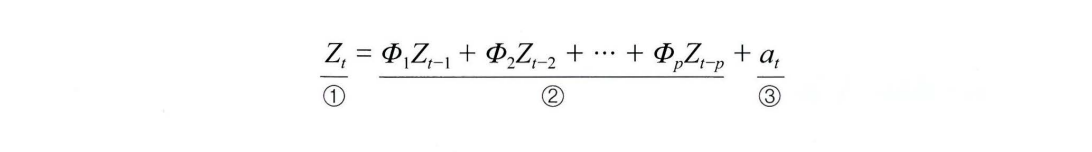

(1) 시계열 데이터에서 현재 시점을 의미
(2) 과거가 현재에 미치는 영향을 나타내는 모수에 시계열 데이터의 과거 시점을 곱한 것
(3) 시계열 분석에서 오차 항을 의미하며 '백색 잡음'이라고도 함

###**MA 모델**

: MA(이동 평균)모델은 트렌드가 변화하는 상황에 적합한 회귀 모델

- 이동 평균 모델에서는 윈도우라는 개념을 사용하는데, 시계열을 따라 윈도우 크기만큼 슬라이딩된다고 해 이동 평균 모델이라고 함

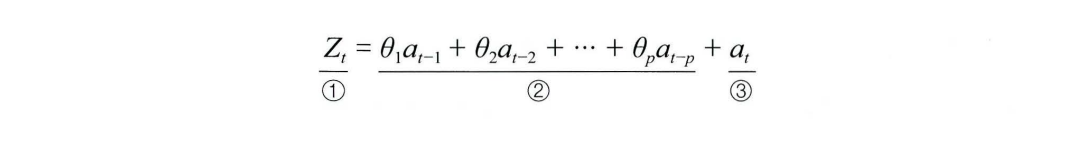

(1) 시계열 데이터에서 현재 시점을 의미
(2) 매개변수에 과거 시점의 오차를 곱한 것
(3) 오차항



###**7.2.3 ARMA 모델**

: ARMA(자기 회귀 이동 평균) 모델은 AR과 MA를 섞은 모델로 연구 기관에서 주로 사용. 즉, AR, MA 두가지 관점에서 과거의 데이터를 사용하는 것이 ARMA

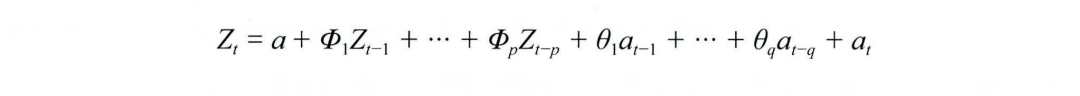

###**ARIMA 모델**

: ARIM(자기 회귀 누적 이동 평균) 모델은 자기 회귀와 이동 평균을 둘 다 고려하는 모형인데, ARMA와 달리 과거 데이터의 선형 관계뿐만 아니라 추세까지 고려한 모델

- statmodels 라이브러리 이용하여 구현

: 검정 및 추정 / 회귀 분석 / 시계열 분석 기능 제공하는 파이썬 패키지

<br>

[모델 구현 절차]

(1) ARIMA(p,d,q) 함수를 호출하여 사용
- p: 자기 회귀 차수
- d: 차분 차수
- q: 이동 평균 차수

(2) fit() 메서드를 호출하고 모델에 데이터를 적용하여 훈련

(3) predict() 메서드를 호출하여 미래의 추세 및 동향에 대해 예측

In [2]:
# statsmodels 모델 설치
!pip install statsmodels

In [3]:
# 데이터셋
!git clone https://github.com/gilbutITbook/080289.git

Cloning into '080289'...
remote: Enumerating objects: 2278, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2278 (delta 3), reused 2 (delta 2), pack-reused 2262 (from 2)
Receiving objects: 100% (2278/2278), 330.29 MiB | 25.53 MiB/s, done.
Resolving deltas: 100% (13/13), done.
Updating files: 100% (2591/2591), done.


/tmp/ipykernel_526/963244588.py:11: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                  Sales   No. Observations:                   36
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -199.651
Date:                Thu, 12 Nov 2026   AIC                            411.302
Time:                        18:24:42   BIC                            420.634
Sample:                    01-01-1991   HQIC                           414.523
                         - 12-01-1993                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8788      0.227     -3.876      0.000      -1.323      -0.434
ar.L2         -0.2787      0.232     -1.203      0.229      -0.733       0.176
ar.L3         -0.0076      0.270     -0.028      0.9

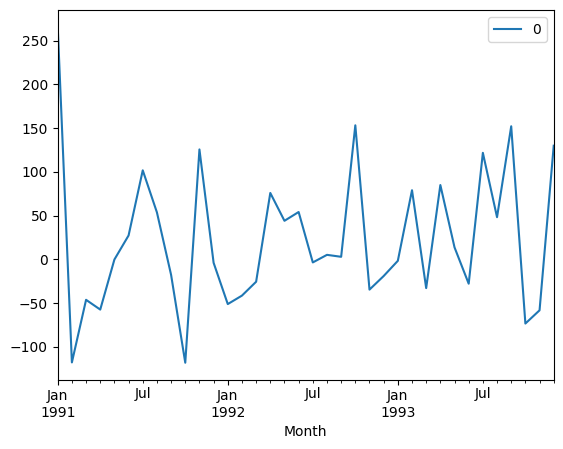

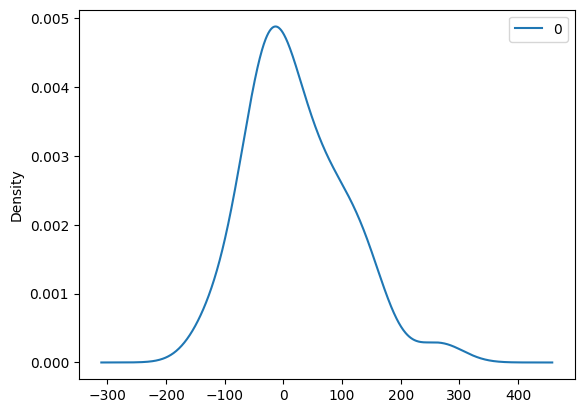

                0
count   36.000000
mean    22.459086
std     82.505331
min   -118.213281
25%    -33.308343
50%      1.361178
75%     76.704967
max    266.000000


In [4]:
# ARIMA() 함수를 호출하여 sales 데이터셋에 대한 예측
from pandas import read_csv # 파이썬 판다스 라이브러리의 read.csv() 메서드를 사용해서 외부 TEXT 파일, CSV 파일을 불러와서 DataFrame으로 저장
from datetime import datetime
from pandas import DataFrame
from statsmodels.tsa.arima.model import ARIMA
from matplotlib import pyplot

def parser(x): # 시간을 표현하는 함수 정의
  return datetime.strptime('199'+x, '%Y-%m') # strptime()은 날짜와 시간 정보를 문자열로 바꾸어 주는 메서드

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,
                  date_parser=parser) # 자전거 매출에 대한 CSV 데이터 호출
model = ARIMA(series, order=(5,1,0)) # ARIMA() 함수 호출
model_fit = model.fit()
print(model_fit.summary()) # 모델에 대한 정보 표시
residuals = DataFrame(model_fit.resid) # DataFrame에 모델에 대한 오차 정보를 residuals라는 변수에 저장
residuals.plot() # 잔차 정보 시각적 표현
pyplot.show()
residuals.plot(kind='kde')
pyplot.show()
print(residuals.describe())

- 실행 결과는 오류 분포가 표시되는데, 결과를 보면 값이 치우쳐 있음을 확인할 수 있음


/tmp/ipykernel_526/4190992845.py:12: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,


predicted=352.855343, expected=346.300000
predicted=277.398036, expected=329.700000
predicted=368.753734, expected=445.400000
predicted=331.773634, expected=325.900000
predicted=372.070405, expected=449.300000
predicted=360.020872, expected=411.300000
predicted=454.526230, expected=417.400000
predicted=388.690691, expected=545.500000
predicted=437.632447, expected=477.600000
predicted=516.437624, expected=687.000000
predicted=520.916191, expected=435.300000
predicted=675.594647, expected=587.300000
predicted=505.201016, expected=676.900000
Test MSE: 9118.819


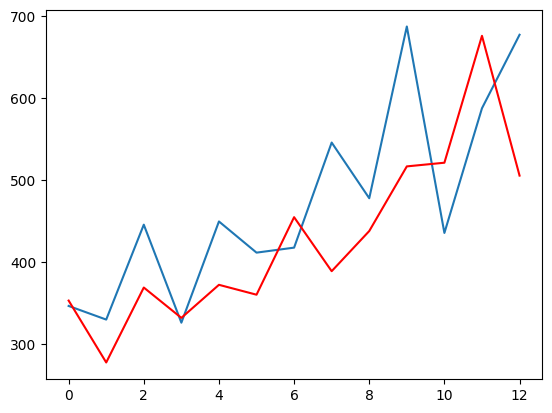

In [5]:
# statsmodels 라이브러리를 이용한 sales 데이터셋 예측
import numpy as np
from pandas import read_csv
from datetime import datetime
from matplotlib import pyplot
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

def parser(x):
    return datetime.strptime('199' + x, '%Y-%m')

series = read_csv('/content/080289/chap07/data/sales.csv', header=0, parse_dates=[0], index_col=0,
                  date_parser=parser)

X = series.values.flatten()
X = np.nan_to_num(X)
size = int(len(X) * 0.66)
train, test = X[0:size], X[size:len(X)]  # train과 test로 데이터셋 분리

history = [x for x in train]
predictions = list()

for t in range(len(test)):  # test 데이터셋의 길이(13)만큼 반복하여 수행
    model = ARIMA(history, order=(5, 1, 0))  # ARIMA() 함수 호출
    model_fit = model.fit()
    output = model_fit.forecast()  # forecast() 메서드를 사용하여 예측 수행
    yhat = output[0]  # 모델 출력 결과를 yhat에 저장
    predictions.append(yhat)
    obs = test[t]
    history.append(obs)
    print('predicted=%f, expected=%f' % (yhat, obs)) # 모델 실행 결과를 predicted로 출력하고, test로 분리해 둔 데이터를 expected로 사용하여 출력
error = mean_squared_error(test, predictions)  # 손실 함수로 평균 제곱 오차 사용
print('Test MSE: %.3f' % error)
pyplot.plot(test)
pyplot.plot(predictions, color='red')
pyplot.show()

- 실제 데이터(빨간색)과 모형 실행 결과(파란색)를 표시한 그림이 만들어짐
- 데이터가 우상향 추세를 나타내고 있으므로, 자전거 판매가 향후에도 계속 증가할 것임을 예측할 수 있음

##**7.3 순환 신경망 (RNN)**

: 시간적으로 연속성이 있는 데이터를 처리하려고 고안된 인공 신경망

- RNN이 기존 네트워크와 다른 점은 '기억'(헌재까지 입력 데이터를 요약한 정보)을 갖는다는 것.
- 따라서 새로운 입력이 네트워크로 들어올 때마다 기억은 조금씩 수정되며, 결국 최종적으로 남겨진 기억은 모든 입력 전체를 요약한 정보가 됨

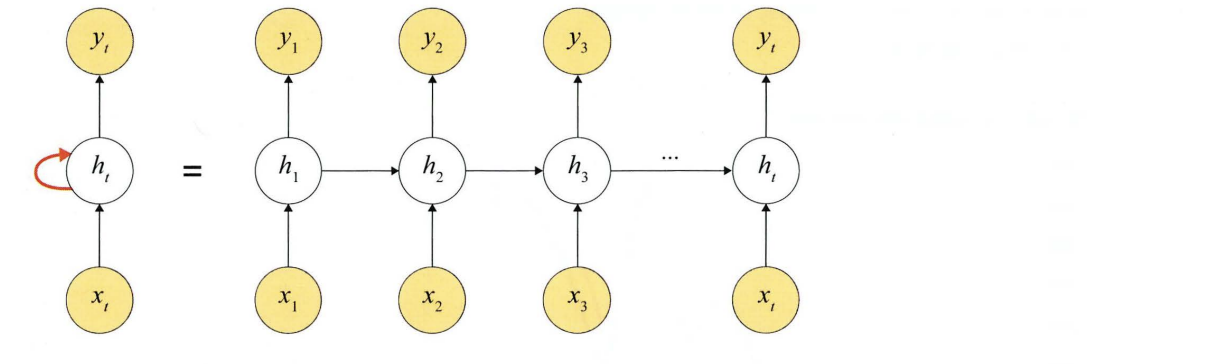

- 첫 번째 입력(x1)이 들어오면 첫 번째 기억(h1)이 만들어지고, 두 번째 입력(x2)이 들어오면 기존 기억(h1)과 새로운 입력을 참고하여 새 기억(h2)를 만듦

> 즉, RNN은 외부 입력과 자신의 이전 상태를 입력받아 현재 상태를 갱신

(1) 일대일: 순환이 없기 때문에 RNN이라고 말하기 어려우며, 순방향 네트워크가 대표적 사례

(2) 일대다: 입력이 하나이고, 출력이 다수인 구조.

(3) 다대일: 입력이 다수이고 출력이 하나인 구조.

In [6]:
# 다대일에 대한 모델 구현
# self.em = nn.Embedding(len(TEXT.vocab.stoi), embedding_dim)  # 임베딩 처리
#self.rnn = nn.RNNCell(input_dim, hidden_size)  # RNN 적용
#self.fc1 = nn.Linear(hidden_size, 256)  # 완전연결층
#self.fc2 = nn.Linear(256, 3)  # 출력층

- 코드는 입력과 출력 사이에 하나의 RNN 셀만 가지고 있는 것에 주의

(4) 다대다: 입력과 출력이 다수인 구조. 파이토치에서는 문장 번역에서 많이 사용되는 시퀀스-투-시퀀스를 이용하는 방식으로 사용됨

In [7]:
# Seq2Seq(
#    (encoder): Encoder(
#        (embedding): Embedding(7855 , 256)
#        (rnn): LSTM(256, 512, num_layers=2, dropout=0.5)
#        (dropout): Dropout( p=0.5, inplace=False)
#)
#(decoder): Decoder(
#    (embedding): Embedding(5893, 256)
#    (rnn): LSTM(256, 512, num_layers=2, dropout=0.5)
#    (fc_out): Linear(in_features =512, out_features=5893, bias=True)
#    (dropout): Dropout( p=0.5 , inplace=False)
#   )
#)

(5) 동기화 다대다: 입력과 출력이 다수인 구조.

###**7.3.1 RNN 계층과 셀**

> RNN 계층이 입력된 배치 순서대로 모두 처리하는 것과 다르게 RNN 셀은 오직 하나의 단계만 처리

- 따라서 RNN 셀은 RNN 계층의 for loop 구문을 갖는 구조라고 할 수 있음
- RNN 계층은 셀을 래핑하여 동일한 셀을 여러 단계에 적용. 즉, 셀은 실제 계산에 사용되는 RNN 계층의 구성요소로, 단일 입력과 과거 상태를 가져와서 출력과 새로운 상태를 생성

[셀 유형]
- nn.RNNCell
- nn.GRUCell
- nn.LSTMCell

> 파이토치에서 RNN의 계층과 셀은 분리해서 구현이 가능
